# 01 — Exploratory Data Analysis

This walkthrough uses the real 64,000-customer Hillstrom email experiment. DuckDB is the main analytical engine. The reusable SQL and Python modules remain the primary implementation.

**Learning goals:** understand the randomized groups, query the analytical view, summarize customer history, and connect descriptive patterns to marketing questions.

In [1]:
from pathlib import Path
ROOT = Path.cwd()
if not (ROOT / "reports").exists(): ROOT = ROOT.parent
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
connection = duckdb.connect(str(ROOT / "data/processed/hillstrom.duckdb"), read_only=True)
print(connection.execute("SELECT COUNT(*) AS customers FROM customer_experiment_analysis").df())

   customers
0      64000


## The analytical view

The view joins normalized customer attributes, randomized assignment, and outcomes. A customer appears once, so assigned-customer rates retain the correct denominator. The source `segment` field is represented as `treatment_group`; it is not a pretreatment predictor.

In [2]:
group_sql = """
SELECT treatment_group, COUNT(*) AS assigned_customers,
       SUM(visit) AS visitors, SUM(conversion) AS purchasers,
       AVG(visit) AS visit_rate, AVG(conversion) AS conversion_rate
FROM customer_experiment_analysis
GROUP BY treatment_group
ORDER BY treatment_group
"""
groups = connection.execute(group_sql).df()
groups

,treatment_group,assigned_customers,visitors,purchasers,visit_rate,conversion_rate
0,Mens E-Mail,21307,3894.0,267.0,0.182757,0.012531
1,No E-Mail,21306,2262.0,122.0,0.106167,0.005726
2,Womens E-Mail,21387,3238.0,189.0,0.151400,0.008837


In [3]:
history_sql = """
SELECT history_segment, treatment_group, COUNT(*) AS customers,
       AVG(history) AS average_historical_spend, AVG(visit) AS visit_rate
FROM customer_experiment_analysis
GROUP BY history_segment, treatment_group
ORDER BY history_segment, treatment_group
"""
segments = connection.execute(history_sql).df()
segments.head(12)

,history_segment,treatment_group,customers,average_historical_spend,visit_rate
0,1) $0 - $100,Mens E-Mail,7724,51.685487,0.153418
1,1) $0 - $100,No E-Mail,7612,51.603710,0.084866
2,1) $0 - $100,Womens E-Mail,7634,51.661992,0.131648
3,2) $100 - $200,Mens E-Mail,4691,146.504266,0.160094
4,2) $100 - $200,No E-Mail,4836,146.165376,0.090984
5,2) $100 - $200,Womens E-Mail,4727,146.694184,0.133488
6,3) $200 - $350,Mens E-Mail,4090,266.791054,0.210758
7,3) $200 - $350,No E-Mail,4044,267.371335,0.126360
8,3) $200 - $350,Womens E-Mail,4155,266.548869,0.162455
9,4) $350 - $500,Mens E-Mail,2097,418.234845,0.239390


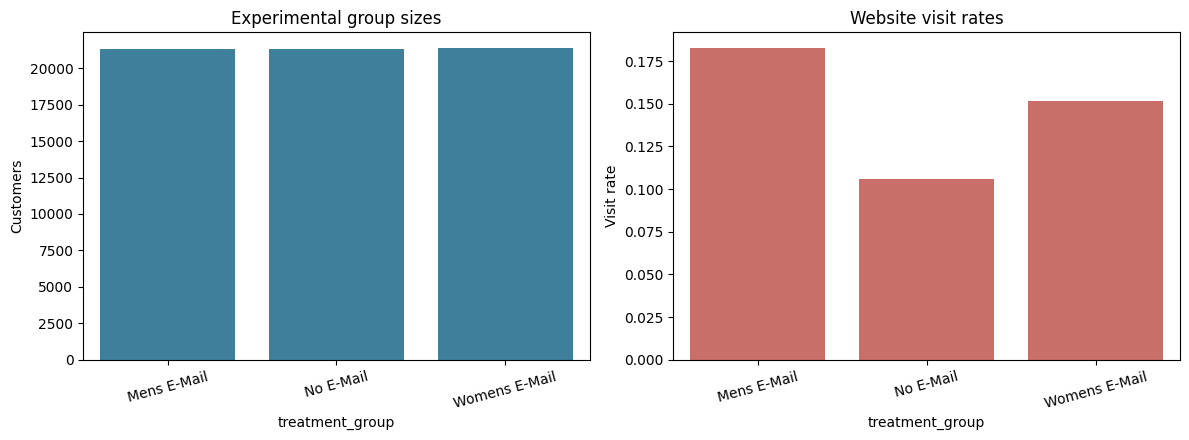

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.barplot(data=groups, x="treatment_group", y="assigned_customers", ax=axes[0], color="#2E86AB")
sns.barplot(data=groups, x="treatment_group", y="visit_rate", ax=axes[1], color="#D95F59")
axes[0].set(title="Experimental group sizes", ylabel="Customers")
axes[1].set(title="Website visit rates", ylabel="Visit rate")
for axis in axes: axis.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

## Business interpretation

Mens E-Mail has the highest observed visit rate, while the groups are approximately equal in size. Historical spending and recency are useful descriptive dimensions, but subgroup differences should not be treated as separate causal claims without appropriately powered randomized comparisons.

## Key Findings

- The analytical view contains 64,000 customers and preserves one row per customer.
- Randomized groups are close to equal in size.
- Mens E-Mail has the highest observed visit rate in the experiment.
- Descriptive customer-history patterns motivate, but do not replace, randomized testing.